# Delta Hedging: Where an Option Dealer's P&L Really Comes From

**Question:** Black-Scholes says an option can be replicated exactly by continuously trading the underlying. A dealer who sells the option at the fair price and hedges should therefore end with zero P&L. In practice the dealer rebalances only now and then, does not know the volatility, and pays to trade. What does the hedged P&L look like under each of these frictions? And when a real dealer sells Bitcoin options at the market's implied volatility and hedges every day, do they make money?

This notebook:

1. Implements the Black-Scholes price and Greeks and checks them against finite differences, put-call parity and the Black-Scholes PDE.
2. Shows the nonlinearity of options. Gamma and the option's leverage both explode near expiry, close to the strike.
3. Simulates discrete hedging and confirms the Derman–Kamal (1999) rule: the hedging error shrinks only as $1/\sqrt{N}$.
4. Hedges with the wrong volatility (Ahmad & Wilmott, 2005). The total profit is set by implied vs realized volatility. The choice of hedging volatility decides whether that profit is certain at the end or smooth along the way.
5. Adds transaction costs. Hedging more often reduces risk but raises costs, which Leland (1985) prices as a higher volatility.
6. Sells a 30-day at-the-money BTC call every day from March 2021 to September 2026 at Deribit's DVOL implied volatility. Each call is hedged daily on real Binance prices, and the test measures the volatility risk premium.

*Inspired by WQU MScFE 560, Module 4 (Leverage and Nonlinearity): option payoffs, options as leverage, and puts as insurance.*

In [1]:
import json
import subprocess
import sys
import urllib.request
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import norm
import statsmodels.api as sm

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3})
ANN = 365        # crypto trades every day of the year
COST = 0.0010    # hedging cost: 10 bp of the value of BTC bought or sold
rng = np.random.default_rng(42)

## 1. Data

Two daily series:

* **BTC/USDT closes** from Binance, downloaded with `src/data.py`.
* **DVOL**, Deribit's 30-day BTC implied volatility index, built from Deribit option prices in the same way as the VIX. It starts on 2021-03-24. It is downloaded from Deribit's public API and cached in `src/data/`.

Both are stamped at 00:00 UTC, so the BTC close and the DVOL close on the same row are observed at the same moment. Interest rates are set to zero throughout. For a USDT-margined hedge this is a simplification, but it is small relative to the effects measured here.

In [2]:
# src/ sits next to the topic folders: one level up in the repo, two levels up locally (W*/<Topic>/)
SRC = next(p / "src" for p in Path.cwd().resolve().parents if (p / "src" / "data.py").exists())
START, END = "2021-03-24", "2026-10-01"   # DVOL starts on 2021-03-24

cmd = [sys.executable, str(SRC / "data.py"), "BTC/USDT", "--since", "2021-01-01", "--until", END, "--full"]
result = subprocess.run(cmd, capture_output=True, text=True)
print("BTC: downloaded from Binance" if result.returncode == 0 else "BTC: download failed, using existing CSV in src/data")
btc = pd.read_csv(SRC / "data" / "BINANCE_BTC-USDT_1d.csv", parse_dates=["Date"], index_col="Date")["Close"]


def fetch_dvol(currency, start, end):
    """Daily DVOL candles from Deribit's public API, paging backwards from `end`."""
    t0, t1 = (int(pd.Timestamp(d, tz="UTC").timestamp() * 1000) for d in (start, end))
    rows = []
    while True:
        url = ("https://www.deribit.com/api/v2/public/get_volatility_index_data"
               f"?currency={currency}&start_timestamp={t0}&end_timestamp={t1}&resolution=1D")
        page = json.load(urllib.request.urlopen(url, timeout=30))["result"]
        rows += page["data"]
        if not page["data"] or not page.get("continuation"):
            break
        t1 = page["continuation"]
    df = pd.DataFrame(rows, columns=["Date", "Open", "High", "Low", "Close"])
    df["Date"] = pd.to_datetime(df["Date"], unit="ms")
    return df.drop_duplicates("Date").sort_values("Date").set_index("Date")


dvol_path = SRC / "data" / "DERIBIT_BTC_DVOL_1d.csv"
try:
    fetch_dvol("BTC", START, END).to_csv(dvol_path)
    print("DVOL: downloaded from Deribit")
except Exception as e:
    print(f"DVOL: download failed ({type(e).__name__}), using existing CSV in src/data")
dvol = pd.read_csv(dvol_path, parse_dates=["Date"], index_col="Date")["Close"] / 100

data = pd.concat({"S": btc, "IV": dvol}, axis=1).loc[START:END].dropna()
data = data[data.index < END]
print(f"{len(data)} days: {data.index[0].date()} → {data.index[-1].date()}")

BTC: downloaded from Binance


DVOL: downloaded from Deribit
2017 days: 2021-03-24 → 2026-09-30


## 2. Black-Scholes price and Greeks

For a call with spot $S$, strike $K$, time to expiry $T$, volatility $\sigma$ and rate $r$:

$$C = S\,N(d_1) - K e^{-rT} N(d_2), \qquad d_{1,2} = \frac{\ln(S/K) + (r \pm \tfrac12\sigma^2)T}{\sigma\sqrt{T}}$$

The Greeks used below are delta $\Delta = N(d_1)$, gamma $\Gamma = \varphi(d_1)/(S\sigma\sqrt T)$, vega $= S\varphi(d_1)\sqrt T$ and theta. The cell checks the analytic formulas three ways: against finite differences, against put-call parity $C - P = S - Ke^{-rT}$, and against the Black-Scholes PDE $\Theta + \tfrac12\sigma^2S^2\Gamma + rS\Delta - rV = 0$. The PDE check matters most for the rest of the notebook. It says the time decay a hedged option holder pays (theta) is exactly the compensation for gamma.

In [3]:
def bs(S, K, T, sigma, r=0.0, kind="call"):
    """Black-Scholes price and Greeks. Vega per unit of vol (1.00 = 100 vol points), theta per year."""
    S, K, T, sigma = (np.asarray(x, dtype=float) for x in (S, K, T, sigma))
    sqT = np.sqrt(T)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqT)
    d2 = d1 - sigma * sqT
    disc = np.exp(-r * T)
    if kind == "call":
        price = S * norm.cdf(d1) - K * disc * norm.cdf(d2)
        delta = norm.cdf(d1)
        theta = -S * norm.pdf(d1) * sigma / (2 * sqT) - r * K * disc * norm.cdf(d2)
    else:
        price = K * disc * norm.cdf(-d2) - S * norm.cdf(-d1)
        delta = norm.cdf(d1) - 1
        theta = -S * norm.pdf(d1) * sigma / (2 * sqT) + r * K * disc * norm.cdf(-d2)
    gamma = norm.pdf(d1) / (S * sigma * sqT)
    vega = S * norm.pdf(d1) * sqT
    return {"price": price, "delta": delta, "gamma": gamma, "vega": vega, "theta": theta}


# check against finite differences and put-call parity
S0, K0, T0, s0, r0 = 100.0, 105.0, 0.25, 0.6, 0.03
g = bs(S0, K0, T0, s0, r0)
h = 1e-4
fd = {"delta": (bs(S0 + h, K0, T0, s0, r0)["price"] - bs(S0 - h, K0, T0, s0, r0)["price"]) / (2 * h),
      "gamma": (bs(S0 + h, K0, T0, s0, r0)["price"] - 2 * g["price"] + bs(S0 - h, K0, T0, s0, r0)["price"]) / h**2,
      "vega": (bs(S0, K0, T0, s0 + h, r0)["price"] - bs(S0, K0, T0, s0 - h, r0)["price"]) / (2 * h),
      "theta": -(bs(S0, K0, T0 + h, s0, r0)["price"] - bs(S0, K0, T0 - h, s0, r0)["price"]) / (2 * h)}
check = pd.DataFrame({"Analytic": {k: float(g[k]) for k in fd}, "Finite difference": {k: float(v) for k, v in fd.items()}})
check["Abs. error"] = (check["Analytic"] - check["Finite difference"]).abs()
display(check.style.format("{:.6f}"))
parity = g["price"] - bs(S0, K0, T0, s0, r0, "put")["price"] - (S0 - K0 * np.exp(-r0 * T0))
theta_gamma = g["theta"] + 0.5 * s0**2 * S0**2 * g["gamma"] + r0 * S0 * g["delta"] - r0 * g["price"]
print(f"Put-call parity residual C - P - (S - K e^-rT): {float(parity):.2e}")
print(f"Black-Scholes PDE residual Θ + ½σ²S²Γ + rSΔ - rV: {float(theta_gamma):.2e}")

,Analytic,Finite difference,Abs. error
delta,0.504933,0.504933,0.000000
gamma,0.013297,0.013297,0.000000
vega,19.945589,19.945589,0.000000
theta,-25.144065,-25.144065,0.000000


Put-call parity residual C - P - (S - K e^-rT): 0.00e+00
Black-Scholes PDE residual Θ + ½σ²S²Γ + rSΔ - rV: -2.50e-15


All three checks pass to machine precision.

Module 4 describes a call as a leveraged position in the underlying. The bottom-right panel makes that precise with the option's **elasticity** $\Delta S / V$: the percentage change in the option for a 1% move in the underlying. A 30-day at-the-money call at 60% vol has elasticity of about 8. Out of the money and close to expiry it reaches into the hundreds. Gamma is the curvature that makes this leverage nonlinear. It is concentrated near the strike and grows sharply as expiry approaches, while theta is its mirror image.

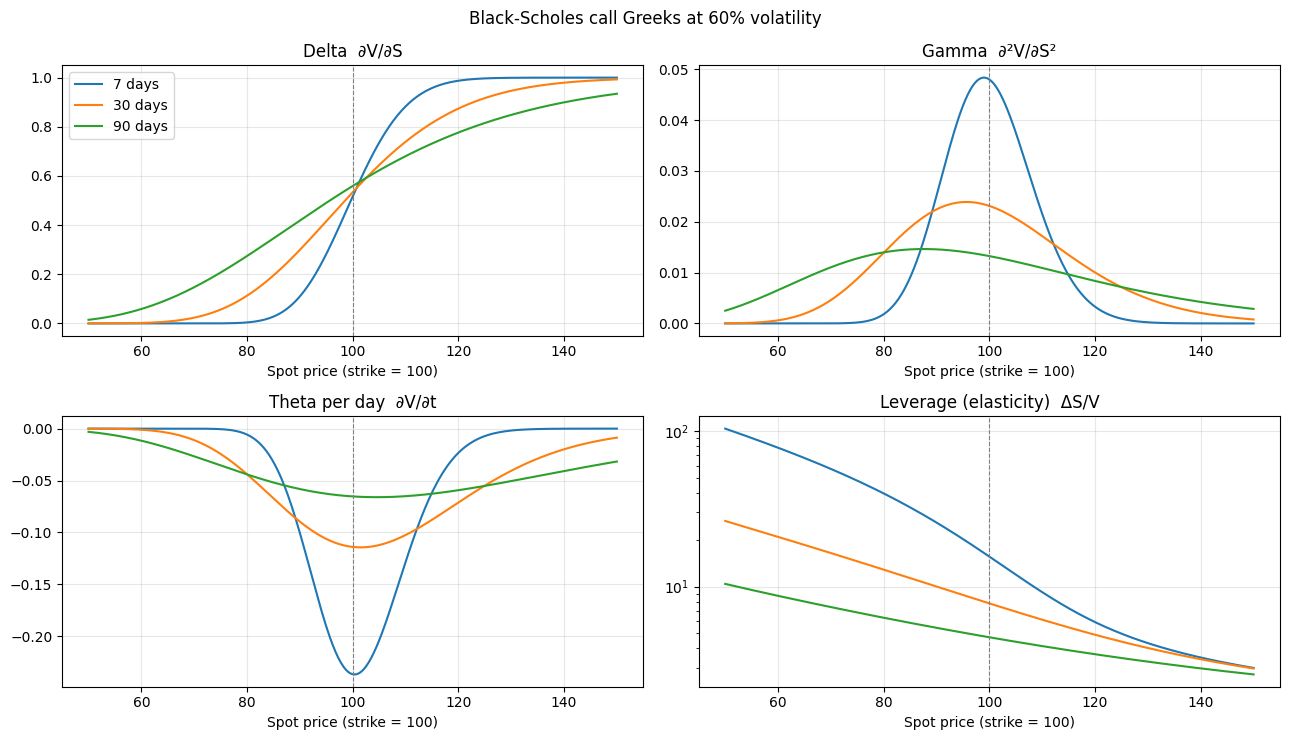

In [4]:
S_grid = np.linspace(50, 150, 401)
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for days in [7, 30, 90]:
    gk = bs(S_grid, 100, days / ANN, 0.6)
    lev = gk["delta"] * S_grid / gk["price"]
    axes[0, 0].plot(S_grid, gk["delta"], label=f"{days} days")
    axes[0, 1].plot(S_grid, gk["gamma"], label=f"{days} days")
    axes[1, 0].plot(S_grid, gk["theta"] / ANN, label=f"{days} days")
    axes[1, 1].plot(S_grid, lev, label=f"{days} days")
for ax, title in zip(axes.flat, ["Delta  ∂V/∂S", "Gamma  ∂²V/∂S²", "Theta per day  ∂V/∂t",
                                 "Leverage (elasticity)  ΔS/V"]):
    ax.set_title(title)
    ax.axvline(100, color="gray", lw=0.8, ls="--")
    ax.set_xlabel("Spot price (strike = 100)")
axes[1, 1].set_yscale("log")
axes[0, 0].legend()
fig.suptitle("Black-Scholes call Greeks at 60% volatility")
plt.tight_layout()
plt.show()

## 3. Discrete hedging: the error that never goes away

A dealer sells the option for its Black-Scholes value and holds $\Delta$ units of the underlying, rebalancing $N$ times before expiry. With continuous rebalancing the final P&L would be exactly zero on every path. With discrete rebalancing, the stock moves between rebalances while the hedge stays fixed, and gamma turns those moves into P&L.

The two helpers below are reused for the rest of the notebook. `simulate_paths` draws geometric Brownian motion paths. `hedge_short_option` sells an option priced at one volatility, hedges it with a delta computed at a (possibly different) volatility, and can charge a proportional cost on every trade.

In [5]:
def simulate_paths(S0, sigma, T, n_steps, n_paths, mu=0.0, seed=0):
    """Geometric Brownian motion sampled at n_steps + 1 evenly spaced times (columns)."""
    z = np.random.default_rng(seed).standard_normal((n_paths, n_steps))
    dt = T / n_steps
    log_inc = (mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z
    return S0 * np.exp(np.hstack([np.zeros((n_paths, 1)), np.cumsum(log_inc, axis=1)]))


def hedge_short_option(paths, K, T, sigma_price, sigma_hedge, kind="call", r=0.0, cost=0.0, every=1):
    """Sell the option at sigma_price, delta-hedge at sigma_hedge every `every` steps (r = 0 cash).

    Returns the final P&L of the hedged short position and the total trading cost paid, per path.
    """
    n_steps = paths.shape[1] - 1
    t = np.linspace(0, T, n_steps + 1)
    premium = bs(paths[:, 0], K, T, sigma_price, r, kind)["price"]
    pos = np.zeros(paths.shape[0])
    hedge_pnl = np.zeros(paths.shape[0])
    costs = np.zeros(paths.shape[0])
    for k in range(n_steps):
        if k % every == 0:
            new = bs(paths[:, k], K, T - t[k], sigma_hedge, r, kind)["delta"]
            costs += cost * np.abs(new - pos) * paths[:, k]
            pos = new
        hedge_pnl += pos * (paths[:, k + 1] - paths[:, k])
    costs += cost * np.abs(pos) * paths[:, -1]     # unwind the hedge at expiry
    payoff = np.maximum(paths[:, -1] - K, 0) if kind == "call" else np.maximum(K - paths[:, -1], 0)
    return premium - payoff + hedge_pnl - costs, costs

Derman & Kamal (1999) used a one-month at-the-money put on a stock with 20% volatility. They showed the standard deviation of the hedged P&L is approximately

$$\sigma_{P\&L} \approx \sqrt{\frac{\pi}{4}}\;\frac{\text{vega}\cdot\sigma}{\sqrt{N}}.$$

The intuition: hedging $N$ times samples the volatility only $N$ times, and a volatility estimated from $N$ returns has error $\approx \sigma/\sqrt{2N}$. The P&L error is the option's sensitivity to volatility times that error. Below, we hedge the same option on 50,000 simulated paths for each $N$.

1-month ATM put, σ = 20%: premium 2.303, vega 0.1151 per vol point
Skewness of the final P&L: N=5: -0.52, N=10: -0.42, N=21: -0.28, N=42: -0.22, N=84: -0.17, N=168: -0.15, N=336: -0.10


,Mean P&L,Std P&L (simulated),Std P&L (Derman-Kamal),Std / premium
Rebalances N,,,,
5,-0.0043,0.8378,0.9125,36.4%
10,-0.0022,0.6094,0.6452,26.5%
21,+0.0007,0.4266,0.4452,18.5%
42,+0.0008,0.3055,0.3148,13.3%
84,+0.0004,0.2193,0.2226,9.5%
168,+0.0001,0.1556,0.1574,6.8%
336,-0.0000,0.1098,0.1113,4.8%


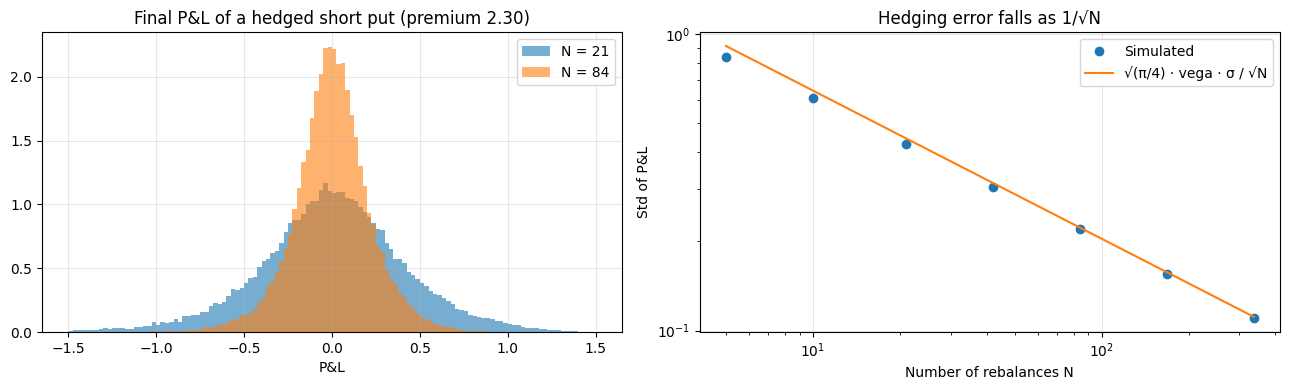

In [6]:
S0, K, T, sigma = 100.0, 100.0, 1 / 12, 0.20
put = bs(S0, K, T, sigma, kind="put")
rows, pnl_by_n = [], {}
for N in [5, 10, 21, 42, 84, 168, 336]:
    paths = simulate_paths(S0, sigma, T, N, 50_000, seed=N)
    pnl, _ = hedge_short_option(paths, K, T, sigma, sigma, kind="put")
    pnl_by_n[N] = pnl
    rows.append({"Rebalances N": N, "Mean P&L": pnl.mean(), "Std P&L (simulated)": pnl.std(),
                 "Std P&L (Derman-Kamal)": np.sqrt(np.pi / 4) * put["vega"] * sigma / np.sqrt(N),
                 "Std / premium": pnl.std() / put["price"]})
dk = pd.DataFrame(rows).set_index("Rebalances N")
print(f"1-month ATM put, σ = 20%: premium {float(put['price']):.3f}, vega {float(put['vega']) / 100:.4f} per vol point")
print("Skewness of the final P&L: " + ", ".join(f"N={n}: {pd.Series(p).skew():.2f}" for n, p in pnl_by_n.items()))
display(dk.style.format({"Mean P&L": "{:+.4f}", "Std P&L (simulated)": "{:.4f}",
                         "Std P&L (Derman-Kamal)": "{:.4f}", "Std / premium": "{:.1%}"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for N in [21, 84]:
    axes[0].hist(pnl_by_n[N], bins=120, range=(-1.5, 1.5), alpha=0.6, density=True, label=f"N = {N}")
axes[0].set_title("Final P&L of a hedged short put (premium 2.30)")
axes[0].set_xlabel("P&L")
axes[0].legend()
axes[1].loglog(dk.index, dk["Std P&L (simulated)"], "o", label="Simulated")
axes[1].loglog(dk.index, dk["Std P&L (Derman-Kamal)"], "-", label="√(π/4) · vega · σ / √N")
axes[1].set_title("Hedging error falls as 1/√N")
axes[1].set_xlabel("Number of rebalances N")
axes[1].set_ylabel("Std of P&L")
axes[1].legend()
plt.tight_layout()
plt.show()

The mean P&L is zero for every $N$: hedging discretely is fair on average. Its spread, though, follows the $\sqrt{\pi/4}\,\text{vega}\,\sigma/\sqrt N$ rule closely (within 6% for $N \ge 10$). The cost of the $1/\sqrt N$ law is harsh. Daily hedging ($N = 21$) leaves a one-standard-deviation error of 18.5% of the premium. Halving it takes four times as many trades, and even hedging 16 times a day leaves almost 5%. The P&L is also slightly left-skewed (skewness −0.28 for $N = 21$). The large losses come from big moves while the spot is near the strike, where the short gamma is largest.

## 4. Hedging with the wrong volatility

In practice the volatility is unknown. Following Ahmad & Wilmott (2005), suppose a trader buys a 30-day at-the-money call at 60% implied volatility while BTC actually realizes 80%. The option is cheap, so there is a profit to be made. The question is how to hedge it:

* **Hedge with the realized vol (80%).** The final profit is fixed at $V(\sigma_{\text{realized}}) - V(\sigma_{\text{implied}})$ on every path (up to the discrete-hedging error from Section 3). Marked at implied vol, though, the position swings randomly before expiry.
* **Hedge with the implied vol (60%).** The mark-to-market changes smoothly, but the final profit depends on the path:

$$P\&L = \tfrac12 \int_0^T \Gamma_i\, S^2 \left(\sigma^2 - \sigma_i^2\right) dt,$$

which in discrete time is $\tfrac12\sum \Gamma_i S^2 (r_t^2 - \sigma_i^2\,\Delta t)$. Profit is earned only when gamma is high, i.e. when the spot is near the strike. A path that drifts far away from the strike earns little, even with high volatility.

Hedging is hourly here to approximate continuous hedging, so the difference between the two methods is visible.

Known edge V(σ_realized) − V(σ_implied) = 2.276 (premium paid 6.854)


,mean,std,5%,50%,95%
Hedge at implied (60%),2.274,1.029,0.757,2.201,4.078
Hedge at realized (80%),2.275,0.296,1.795,2.274,2.753


Corr(gamma attribution, simulated P&L), implied-vol hedge: 0.999


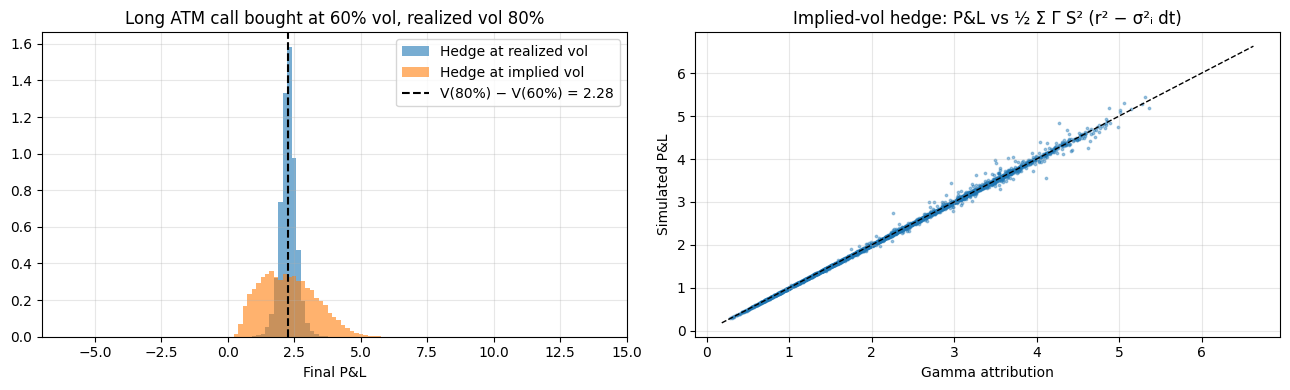

In [7]:
S0, K, T = 100.0, 100.0, 30 / ANN
iv, rv = 0.60, 0.80            # option priced at 60% implied, BTC actually realizes 80%
n_steps, n_paths = 30 * 24, 20_000   # hourly hedging approximates continuous hedging
paths = simulate_paths(S0, rv, T, n_steps, n_paths, seed=7)

# a long option is the mirror image of the short one: flip the sign
pnl_hedge_iv = -hedge_short_option(paths, K, T, iv, iv)[0]
pnl_hedge_rv = -hedge_short_option(paths, K, T, iv, rv)[0]
edge = float(bs(S0, K, T, rv)["price"] - bs(S0, K, T, iv)["price"])

# gamma attribution for the implied-vol hedge: ½ Γ_i S² (realized move² − implied variance · dt)
t = np.linspace(0, T, n_steps + 1)
dt = T / n_steps
gam = bs(paths[:, :-1], K, T - t[:-1], iv)["gamma"]
attrib = (0.5 * gam * paths[:, :-1] ** 2 * ((np.diff(paths, axis=1) / paths[:, :-1]) ** 2 - iv**2 * dt)).sum(axis=1)

summary = pd.DataFrame({"Hedge at implied (60%)": pnl_hedge_iv, "Hedge at realized (80%)": pnl_hedge_rv}).describe(
    percentiles=[0.05, 0.5, 0.95]).T[["mean", "std", "5%", "50%", "95%"]]
print(f"Known edge V(σ_realized) − V(σ_implied) = {edge:.3f} (premium paid {float(bs(S0, K, T, iv)['price']):.3f})")
display(summary.style.format("{:.3f}"))
print(f"Corr(gamma attribution, simulated P&L), implied-vol hedge: {np.corrcoef(attrib, pnl_hedge_iv)[0, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.linspace(-6, 14, 120)
axes[0].hist(pnl_hedge_rv, bins=bins, alpha=0.6, density=True, label="Hedge at realized vol")
axes[0].hist(pnl_hedge_iv, bins=bins, alpha=0.6, density=True, label="Hedge at implied vol")
axes[0].axvline(edge, color="k", ls="--", label=f"V(80%) − V(60%) = {edge:.2f}")
axes[0].set_title("Long ATM call bought at 60% vol, realized vol 80%")
axes[0].set_xlabel("Final P&L")
axes[0].legend()
axes[1].scatter(attrib[:3000], pnl_hedge_iv[:3000], s=3, alpha=0.4)
lim = [min(attrib.min(), pnl_hedge_iv.min()), max(attrib.max(), pnl_hedge_iv.max())]
axes[1].plot(lim, lim, "k--", lw=1)
axes[1].set_title("Implied-vol hedge: P&L vs ½ Σ Γ S² (r² − σ²ᵢ dt)")
axes[1].set_xlabel("Gamma attribution")
axes[1].set_ylabel("Simulated P&L")
plt.tight_layout()
plt.show()

Both hedges earn the same 2.28 on average, a 33% return on the 6.85 premium. With zero drift, the hedge's gains are a martingale and cannot change the expected P&L. What changes is the risk. Hedging at realized vol leaves a standard deviation of 0.30, which is just the residual hourly-hedging error. Hedging at implied vol leaves 1.03, more than three times as much: 5% of paths make less than 0.76, and some lose money despite the 20-vol-point edge. The right panel confirms the gamma formula. The discrete attribution $\tfrac12\sum\Gamma_iS^2(r^2-\sigma_i^2\Delta t)$ has a 0.999 correlation with the simulated P&L.

The trade-off is visible along the path. The two panels below use the same five price paths and mark the long call at implied vol each hour.

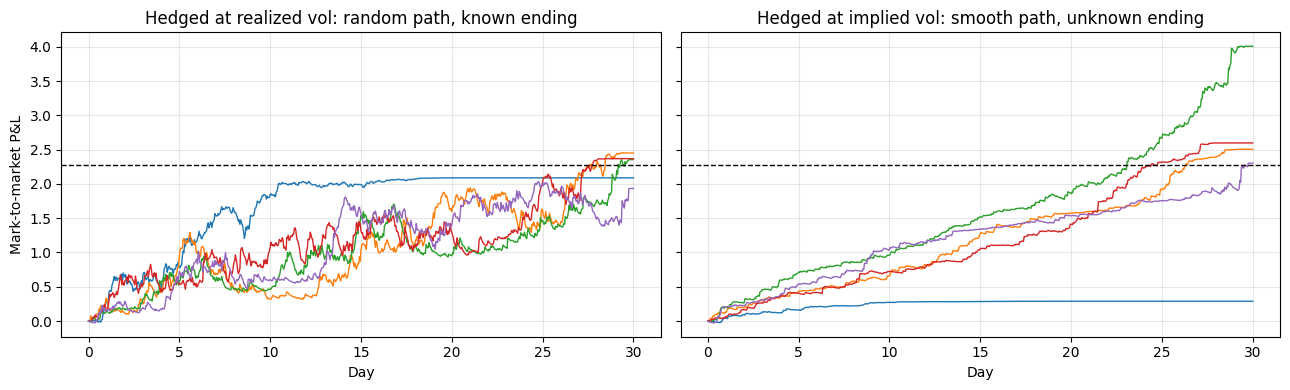

In [8]:
def mtm_path(path, sigma_hedge):
    """Running P&L of the long option marked at implied vol, hedged at sigma_hedge."""
    tau = T - t
    value = bs(path, K, np.maximum(tau, 1e-12), iv)["price"]
    value[-1] = max(path[-1] - K, 0)
    delta = bs(path[:-1], K, tau[:-1], sigma_hedge)["delta"]
    hedge = np.concatenate([[0], np.cumsum(-delta * np.diff(path))])
    return value - value[0] + hedge


fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
days = t * ANN
for i in range(5):
    axes[0].plot(days, mtm_path(paths[i], rv), lw=1)
    axes[1].plot(days, mtm_path(paths[i], iv), lw=1)
for ax, title in zip(axes, ["Hedged at realized vol: random path, known ending",
                            "Hedged at implied vol: smooth path, unknown ending"]):
    ax.axhline(edge, color="k", ls="--", lw=1)
    ax.set_title(title)
    ax.set_xlabel("Day")
axes[0].set_ylabel("Mark-to-market P&L")
plt.tight_layout()
plt.show()

On the left, the paths jump around along the way but all finish close to the dashed line, the known edge of 2.28. What is left is the 0.3 hourly-hedging error. On the right, the P&L builds up smoothly, but the endings range from 0.3 (the blue path, where the spot moved away from the strike early and gamma vanished) to 4.0. Ahmad & Wilmott's conclusion is that the realized-vol hedge needs a correct estimate of future volatility, which is never known. That is one reason most desks hedge at implied: the P&L is smoother and easier to explain each day. The cost is that the final outcome is uncertain.

## 5. Transaction costs

Each rebalance costs money. Here every trade in the hedge pays 10 bp of the value traded, roughly a taker fee on a crypto exchange. The dealer sells a 30-day at-the-money call at 60% vol, its fair price, so the mean P&L equals minus the mean trading cost.

Leland (1985) showed that a dealer who rebalances every $\delta t$ with round-trip cost $k$ should price and hedge with an inflated volatility,

$$\sigma_L^2 = \sigma^2\left(1 + \sqrt{\tfrac{2}{\pi}}\,\frac{k}{\sigma\sqrt{\delta t}}\right),$$

and that the extra premium $V(\sigma_L) - V(\sigma)$ covers the expected cost of rebalancing.

Short 30-day ATM call at 60% vol, premium 6.854, hedging cost 0.10% per trade


,Rebalances,Mean cost,Std P&L,Mean P&L,Leland vol,Leland markup
Frequency,,,,,,
Weekly,4,0.174,2.551,-0.175,60.6%,0.065
Every 3 days,10,0.201,1.815,-0.201,60.9%,0.100
Daily,30,0.278,1.093,-0.280,61.5%,0.172
Every 8 hours,90,0.407,0.654,-0.410,62.6%,0.294
Every 4 hours,180,0.532,0.487,-0.535,63.6%,0.413
Hourly,720,0.958,0.402,-0.958,67.1%,0.803


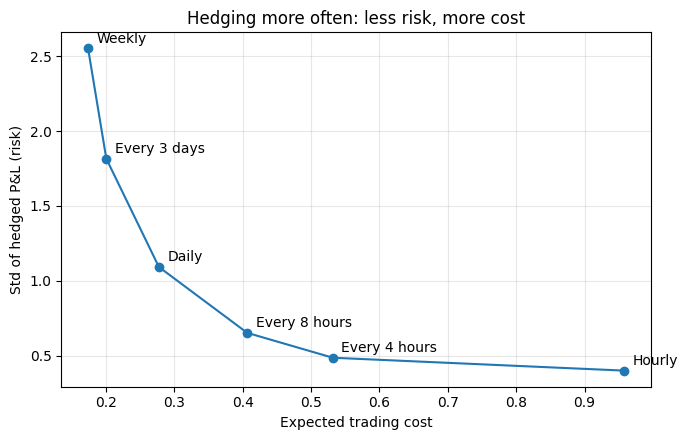

In [9]:
S0, K, T, sigma = 100.0, 100.0, 30 / ANN, 0.60
base = simulate_paths(S0, sigma, T, 30 * 24, 20_000, seed=11)    # hourly grid
premium = float(bs(S0, K, T, sigma)["price"])
rows = []
for label, every in [("Weekly", 168), ("Every 3 days", 72), ("Daily", 24), ("Every 8 hours", 8),
                     ("Every 4 hours", 4), ("Hourly", 1)]:
    pnl, costs = hedge_short_option(base, K, T, sigma, sigma, cost=COST, every=every)
    n_rebal = 30 * 24 / every
    dt_h = T / n_rebal
    leland = sigma * np.sqrt(1 + np.sqrt(2 / np.pi) * (2 * COST) / (sigma * np.sqrt(dt_h)))
    rows.append({"Frequency": label, "Rebalances": int(n_rebal), "Mean cost": costs.mean(),
                 "Std P&L": pnl.std(), "Mean P&L": pnl.mean(),
                 "Leland vol": leland,
                 "Leland markup": float(bs(S0, K, T, leland)["price"]) - premium})
tc = pd.DataFrame(rows).set_index("Frequency")
print(f"Short 30-day ATM call at 60% vol, premium {premium:.3f}, hedging cost {COST:.2%} per trade")
display(tc.style.format({"Mean cost": "{:.3f}", "Std P&L": "{:.3f}", "Mean P&L": "{:+.3f}",
                         "Leland vol": "{:.1%}", "Leland markup": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(tc["Mean cost"], tc["Std P&L"], "o-")
for name, row in tc.iterrows():
    ax.annotate(name, (row["Mean cost"], row["Std P&L"]), textcoords="offset points", xytext=(6, 4))
ax.set_xlabel("Expected trading cost")
ax.set_ylabel("Std of hedged P&L (risk)")
ax.set_title("Hedging more often: less risk, more cost")
plt.tight_layout()
plt.show()

The frontier is the dealer's real choice. Going from weekly to hourly hedging cuts the risk from 2.55 to 0.40 (−84%), but raises the expected cost from 0.17 to 0.96 (5.5×). That is 14% of the premium. Beyond about every 4 hours, extra trades buy little risk reduction, because the risk falls only as $1/\sqrt N$ while the hedge's turnover, and so its cost, keeps growing roughly as $\sqrt N$.

Leland's markup tracks the simulated cost once the fixed cost of opening and closing the hedge is added back. Leland prices only the rebalancing trades. Buying the initial ~0.5 delta and unwinding it at expiry costs about 0.1 here. For daily hedging, 0.172 + 0.1 ≈ 0.28 matches the simulated 0.278. For hourly hedging, 0.80 + 0.1 ≈ 0.90 vs 0.96 simulated.

## 6. Real data: selling BTC volatility at DVOL

Sections 3–5 were simulations in which the true volatility was known. In the market, the dealer sells at the **implied** volatility and is then exposed to whatever volatility BTC **realizes**. Their spread is the volatility risk premium (Carr & Wu, 2009). For equity indices it is reliably positive for option sellers: Bakshi & Kapadia (2003) found that delta-hedged long option positions lose money on average. Alexander & Imeraj (2021) found a premium in bitcoin too, but less stable.

First, a direct comparison: DVOL on each day vs the volatility BTC then realized over the next 30 days.

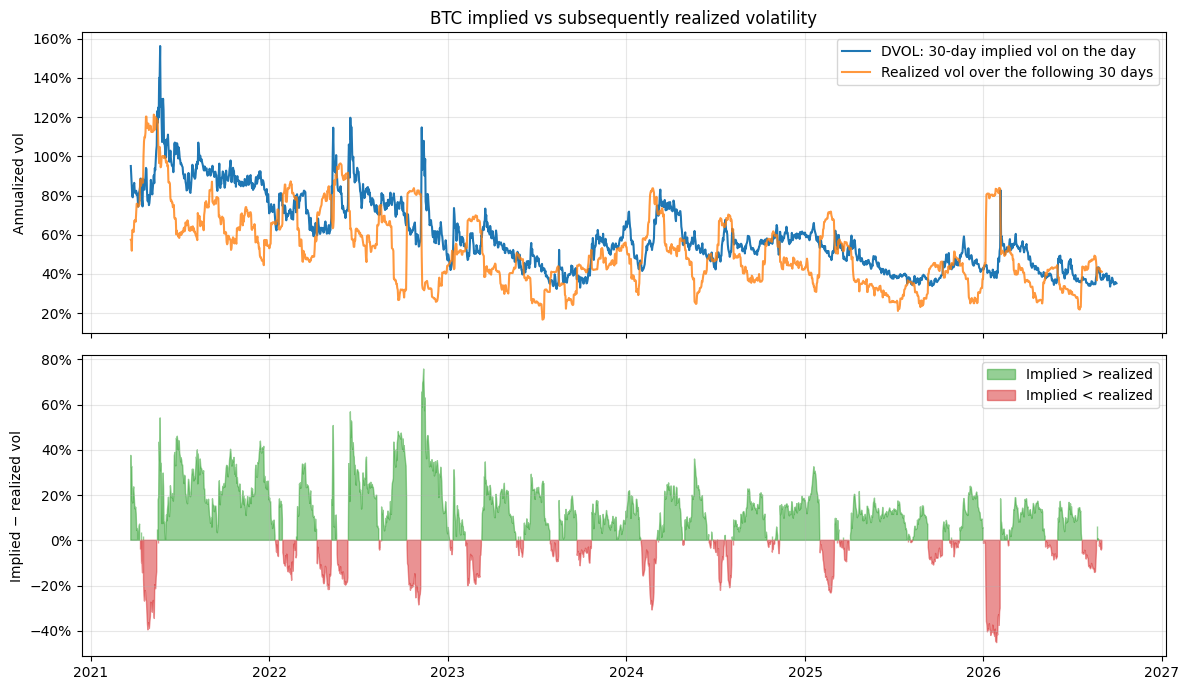

Mean implied 59.8%, mean next-30-day realized 51.7%; implied above realized on 72% of 1987 days


In [10]:
logret = np.log(data["S"]).diff()
fwd_rv = logret[::-1].rolling(30).std()[::-1].shift(-1) * np.sqrt(ANN)   # realized vol over the next 30 days
vrp = (data["IV"] - fwd_rv).dropna()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(data["IV"], label="DVOL: 30-day implied vol on the day")
axes[0].plot(fwd_rv, label="Realized vol over the following 30 days", alpha=0.8)
axes[0].set_ylabel("Annualized vol")
axes[0].legend()
axes[0].set_title("BTC implied vs subsequently realized volatility")
axes[1].fill_between(vrp.index, vrp, 0, where=vrp > 0, color="tab:green", alpha=0.5, label="Implied > realized")
axes[1].fill_between(vrp.index, vrp, 0, where=vrp <= 0, color="tab:red", alpha=0.5, label="Implied < realized")
axes[1].set_ylabel("Implied − realized vol")
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Mean implied {data['IV'].mean():.1%}, mean next-30-day realized {fwd_rv.mean():.1%}; "
      f"implied above realized on {(vrp > 0).mean():.0%} of {len(vrp)} days")

Implied volatility exceeded the volatility that followed on about 72% of days, by about 8 vol points on average. The exceptions come in short episodes when realized volatility jumped above what options had priced. The worst months by this measure were January 2026 (implied 33 points below the realized vol that followed), February 2024, February 2025 and July 2024.

### The hedged short-call backtest

Now the actual trade. Every day $t$:

1. Sell a 30-day call struck at today's close ($K = S_t$), priced by Black-Scholes at that day's DVOL.
2. Hold $\Delta$ BTC, recomputed at each daily close with the same implied vol (the implied-vol hedge of Section 4). Pay 10 bp on every hedge trade, including the initial purchase and the final unwind.
3. At expiry pay the call payoff $\max(S_{t+30} - K, 0)$.

P&L is measured as a percentage of the spot price at sale. A new trade starts every day and each runs for 30 days, so consecutive trades overlap heavily. The t-statistic of the mean therefore uses Newey–West standard errors with 30 lags. Treating 1,987 overlapping trades as independent would overstate the significance by a factor of about 4.

In [11]:
TENOR = 30


def hedged_short_call(i, cost=0.0, iv_shift=0.0):
    """Sell a 30-day ATM call on day i at DVOL + iv_shift, delta-hedge at that implied vol at each daily close."""
    S = data["S"].values[i:i + TENOR + 1]
    iv = data["IV"].values[i] + iv_shift
    tau = (TENOR - np.arange(TENOR)) / ANN
    g = bs(S[:-1], S[0], tau, iv)
    premium = g["price"][0]
    trades = np.abs(np.diff(np.concatenate([[0], g["delta"], [0]])))
    trade_cost = cost * (trades * np.concatenate([S[:-1], [S[-1]]])).sum()
    pnl = premium - max(S[-1] - S[0], 0) + (g["delta"] * np.diff(S)).sum() - trade_cost
    r = np.diff(S) / S[:-1]
    attrib = -(0.5 * g["gamma"] * S[:-1] ** 2 * (r**2 - iv**2 / ANN)).sum()
    rv = np.sqrt(np.sum(np.diff(np.log(S)) ** 2) * ANN / TENOR)
    return {"Date": data.index[i], "S0": S[0], "IV": iv, "RV": rv, "Premium": premium / S[0],
            "P&L": pnl / S[0], "Cost": trade_cost / S[0],
            "Gamma attribution": attrib / S[0]}


bt = pd.DataFrame([hedged_short_call(i, COST) for i in range(len(data) - TENOR)]).set_index("Date")
bt["P&L before costs"] = bt["P&L"] + bt["Cost"]


def hac_mean(x, lags=TENOR):
    """Mean of overlapping trades with a Newey-West t-statistic (trades overlap for 30 days)."""
    fit = sm.OLS(x.values, np.ones(len(x))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return fit.params[0], fit.tvalues[0]


stats_rows = {}
for col in ["P&L before costs", "P&L"]:
    m, tstat = hac_mean(bt[col])
    stats_rows[col] = {"Mean (% of spot)": m, "Newey-West t": tstat, "Win rate": (bt[col] > 0).mean(),
                       "Mean / premium": m / bt["Premium"].mean(), "Worst trade": bt[col].min(),
                       "5% quantile": bt[col].quantile(0.05), "Skewness": bt[col].skew()}
display(pd.DataFrame(stats_rows).T.style.format({"Mean (% of spot)": "{:+.2%}", "Newey-West t": "{:.2f}",
                                                 "Win rate": "{:.0%}", "Mean / premium": "{:.0%}",
                                                 "Worst trade": "{:+.1%}", "5% quantile": "{:+.1%}",
                                                 "Skewness": "{:.2f}"}))
print(f"{len(bt)} overlapping trades; average premium {bt['Premium'].mean():.2%} of spot; "
      f"average hedging cost {bt['Cost'].mean():.2%} of spot")
naive_t = bt["P&L"].mean() / (bt["P&L"].std() / np.sqrt(len(bt)))
print(f"Naive t-statistic treating overlapping trades as independent: {naive_t:.1f}")

,Mean (% of spot),Newey-West t,Win rate,Mean / premium,Worst trade,5% quantile,Skewness
P&L before costs,+1.17%,6.71,73%,17%,-7.7%,-2.0%,0.38
P&L,+0.92%,5.23,69%,13%,-7.9%,-2.3%,0.37


1987 overlapping trades; average premium 6.87% of spot; average hedging cost 0.25% of spot
Naive t-statistic treating overlapping trades as independent: 19.9


Over 5½ years, selling BTC volatility and delta hedging earned **+1.17% of spot per 30-day call before costs and +0.92% after costs**. That is 13% of the premium collected, with a Newey–West t-statistic of 5.2 (the naive t of 19.9 ignores the overlap), and 69% of trades made money. Hedging costs took 0.25% of spot per trade, about a fifth of the gross edge.

One caveat matters more than costs. DVOL is a variance-swap-style index that averages over the whole volatility smile. Because crypto smiles have expensive wings, at-the-money implied vol usually sits a few points *below* DVOL. Selling an at-the-money call at DVOL overstates the premium a real dealer would receive. The next cell repeats the backtest with lower implied vols.

In [12]:
rows = {}
for shift in [0.0, -0.03, -0.05, -0.08]:
    pnl = pd.Series([hedged_short_call(i, COST, shift)["P&L"] for i in range(len(data) - TENOR)])
    m, tstat = hac_mean(pnl)
    rows[f"DVOL {shift * 100:+.0f} vol pts"] = {"Mean P&L after costs": m, "Newey-West t": tstat,
                                                "Win rate": (pnl > 0).mean()}
display(pd.DataFrame(rows).T.style.format({"Mean P&L after costs": "{:+.2%}", "Newey-West t": "{:.2f}",
                                           "Win rate": "{:.0%}"}))

,Mean P&L after costs,Newey-West t,Win rate
DVOL +0 vol pts,+0.92%,5.23,69%
DVOL -3 vol pts,+0.58%,3.34,64%
DVOL -5 vol pts,+0.36%,2.06,59%
DVOL -8 vol pts,+0.02%,0.10,49%


The result survives a 3-vol-point haircut (+0.58%, t = 3.3) and, borderline, 5 points (+0.36%, t = 2.1). At 8 points below DVOL the edge is gone. So the premium is real but thin once execution is realistic. Bid-ask spreads on Deribit options, which are not modelled here, would take part of what remains.

Where does the P&L come from? Section 4 says the implied-vol hedge earns $\tfrac12\sum\Gamma_iS^2(\sigma_i^2\Delta t - r_t^2)$ for the seller: positive when daily moves are smaller than implied, weighted by gamma.

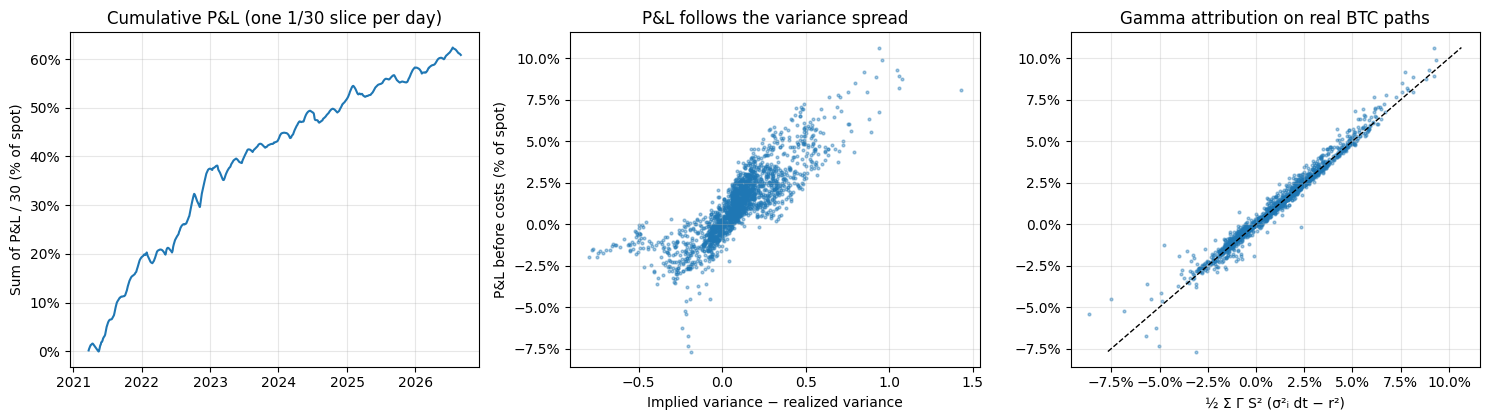

Corr(P&L, implied − realized variance) = 0.84; Corr(P&L, gamma attribution) = 0.99


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].plot(bt["P&L"].cumsum() / TENOR)
axes[0].set_title("Cumulative P&L (one 1/30 slice per day)")
axes[0].set_ylabel("Sum of P&L / 30 (% of spot)")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].scatter(bt["IV"]**2 - bt["RV"]**2, bt["P&L before costs"], s=4, alpha=0.4)
axes[1].set_xlabel("Implied variance − realized variance")
axes[1].set_ylabel("P&L before costs (% of spot)")
axes[1].set_title("P&L follows the variance spread")
axes[2].scatter(bt["Gamma attribution"], bt["P&L before costs"], s=4, alpha=0.4)
lim = [bt["P&L before costs"].min(), bt["P&L before costs"].max()]
axes[2].plot(lim, lim, "k--", lw=1)
axes[2].set_xlabel("½ Σ Γ S² (σ²ᵢ dt − r²)")
axes[2].set_title("Gamma attribution on real BTC paths")
for ax in axes[1:]:
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
axes[2].xaxis.set_major_formatter(PercentFormatter(1.0))
plt.tight_layout()
plt.show()
print(f"Corr(P&L, implied − realized variance) = {np.corrcoef(bt['IV']**2 - bt['RV']**2, bt['P&L before costs'])[0, 1]:.2f}; "
      f"Corr(P&L, gamma attribution) = {np.corrcoef(bt['Gamma attribution'], bt['P&L before costs'])[0, 1]:.2f}")

The real trades behave exactly as the theory says. The gamma attribution, computed from daily closes, has a 0.99 correlation with the actual hedged P&L. The simpler implied-minus-realized variance spread has 0.84; the rest of the variation comes from *when* the big moves happen, and whether the spot is still near the strike at that point. The cumulative P&L rises steadily with occasional sharp drawdowns, the familiar shape of a short-volatility strategy.

### Year by year and worst trades

In [14]:
yearly = bt.groupby(bt.index.year).agg(Trades=("P&L", "size"), IV=("IV", "mean"), RV=("RV", "mean"),
                                        Premium=("Premium", "mean"), PnL=("P&L", "mean"),
                                        Win=("P&L", lambda x: (x > 0).mean()), Worst=("P&L", "min"))
display(yearly.style.format({"IV": "{:.0%}", "RV": "{:.0%}", "Premium": "{:.2%}", "PnL": "{:+.2%}",
                             "Win": "{:.0%}", "Worst": "{:+.1%}"}))
print(bt.nsmallest(5, "P&L")[["S0", "IV", "RV", "P&L"]])

,Trades,IV,RV,Premium,PnL,Win,Worst
Date,,,,,,,
2021,283,92%,74%,10.46%,+2.05%,86%,-2.2%
2022,365,74%,61%,8.40%,+1.50%,68%,-4.8%
2023,365,50%,43%,5.67%,+0.49%,64%,-5.8%
2024,366,58%,51%,6.59%,+0.68%,70%,-7.9%
2025,365,46%,39%,5.26%,+0.53%,65%,-3.2%
2026,243,44%,44%,4.99%,+0.32%,60%,-3.9%


                  S0      IV        RV       P&L
Date                                            
2024-07-09  58050.00  0.5005  0.660667 -0.079268
2024-07-10  57725.85  0.4869  0.662141 -0.077890
2024-07-11  57339.89  0.4854  0.661745 -0.071721
2024-07-12  57889.10  0.4632  0.673369 -0.066633
2023-02-11  21862.55  0.4713  0.663248 -0.057816


The premium was positive in every year. It shrank as the market matured: from +2.05% in 2021, when implied vol averaged 92%, to about +0.3–0.7% in 2023–2026. Over the same period the gap between implied and realized vol narrowed from 18 points to roughly 0–7. In 2026 so far, implied and realized have averaged the same 44%, and the edge has nearly disappeared.

The worst trades are all of the same kind. In July 2024 BTC sat near $58k with implied vol around 46–50%. Over the next month it realized 66%, including the 5 August crash, and the seller lost up to 7.9% of spot. That is about 8.6 times the average gain after costs. Selling volatility earns small, frequent profits and pays for them with occasional large losses when realized volatility jumps above what was priced.

## 7. Takeaways

1. **Delta hedging removes direction, not volatility.** A hedged option's P&L is $\tfrac12\sum\Gamma S^2(r^2 - \sigma_i^2\Delta t)$: gamma-weighted realized variance minus implied variance. This held with correlation 0.999 in simulation and 0.99 on real BTC paths.
2. **Discrete hedging leaves a large, unavoidable error.** It falls only as $1/\sqrt N$: about 18% of the premium for daily hedging of a one-month option, matching the Derman–Kamal rule of thumb.
3. **The choice of hedging volatility changes the risk, not the expected profit.** Hedging at realized vol locks in $V(\sigma)-V(\sigma_i)$ but needs a volatility forecast you do not have. Hedging at implied gives a smooth P&L whose total depends on the path; in the example its spread was three times larger.
4. **Costs set a limit on how often to hedge.** From weekly to hourly hedging, risk fell 84% but expected cost rose 5.5×. Leland's adjusted volatility, plus the cost of opening and closing the hedge, matches the simulated cost.
5. **The BTC volatility risk premium was real but has shrunk.** Selling 30-day at-the-money calls at DVOL and hedging daily earned +0.92% of spot per trade after costs (Newey–West t = 5.2), positive in every year but falling from 2.1% in 2021 to 0.3% in 2026. It survives a 3–5 vol point haircut for the smile, but not 8, and its losses come in sharp clusters when realized volatility spikes.

**Next steps:** use actual Deribit at-the-money option quotes (with bid-ask) instead of DVOL; hedge on a delta band rather than a fixed schedule (Whalley & Wilmott); add a jump-diffusion simulation to measure how much of the left tail discrete hedging cannot remove; and repeat the backtest for ETH.

## References

* Black, F., Scholes, M. (1973). The Pricing of Options and Corporate Liabilities. *Journal of Political Economy* 81(3), 637–654.
* Boyle, P. P., Emanuel, D. (1980). Discretely Adjusted Option Hedges. *Journal of Financial Economics* 8(3), 259–282.
* Leland, H. E. (1985). Option Pricing and Replication with Transactions Costs. *Journal of Finance* 40(5), 1283–1301.
* Derman, E., Kamal, M. (1999). When You Cannot Hedge Continuously: The Corrections to Black-Scholes. *Risk* 12(1), 82–85.
* Bakshi, G., Kapadia, N. (2003). Delta-Hedged Gains and the Negative Market Volatility Risk Premium. *Review of Financial Studies* 16(2), 527–566.
* Ahmad, R., Wilmott, P. (2005). Which Free Lunch Would You Like Today, Sir? Delta Hedging, Volatility Arbitrage and Optimal Portfolios. *Wilmott Magazine*, November, 64–79.
* Carr, P., Wu, L. (2009). Variance Risk Premiums. *Review of Financial Studies* 22(3), 1311–1341.
* Alexander, C., Imeraj, A. (2021). The Bitcoin VIX and Its Variance Risk Premium. *Journal of Alternative Investments* 23(4), 84–109.
* Hull, J. C. *Options, Futures, and Other Derivatives*, 11th ed. Pearson.
* Deribit. DVOL — Deribit Implied Volatility Index. https://insights.deribit.com/?p=1813